## Doing basic data exploration on the decade of state-wise electricity data from Zenodo

### Imports and Paths

In [31]:

# Imports and configuration
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 160)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)


In [32]:

# Locate project directories
current_path = Path.cwd()

project_root = next(
    (
        path for path in [current_path, *current_path.parents]
        if (path / "data" / "raw").is_dir()
    ),
    None
)

if project_root is None:
    raise FileNotFoundError(
        "Project root not found. Run the notebook from within Urja_Niyam."
    )

raw_root = project_root / "data" / "raw"
state_dir = raw_root / "zenodo_state"
mw_dir = raw_root / "zenodo_electricity_MW"
mu_dir = raw_root / "zenodo_electricity_MU"
derived_dir = raw_root / "zenodo_derived"

output_dir = project_root / "outputs" / "eda"
output_dir.mkdir(parents=True, exist_ok=True)

print("Project root:", project_root)
print("Output directory:", output_dir)


Project root: c:\Users\Admin\Projects\Urja_Niyam
Output directory: c:\Users\Admin\Projects\Urja_Niyam\outputs\eda


### Inventory of Files

In [33]:

# File inventory
csv_files = sorted(raw_root.rglob("*.csv"))
inventory_rows = []

for file_path in csv_files:
    try:
        preview = pd.read_csv(file_path, nrows=5)
        inventory_rows.append({
            "file": file_path.name,
            "folder": str(file_path.parent.relative_to(project_root)),
            "columns": len(preview.columns),
            "column_names": list(preview.columns),
            "size_MB": round(file_path.stat().st_size / (1024**2), 2),
            "read_error": None
        })
    except Exception as error:
        inventory_rows.append({
            "file": file_path.name,
            "folder": str(file_path.parent.relative_to(project_root)),
            "columns": None,
            "column_names": None,
            "size_MB": round(file_path.stat().st_size / (1024**2), 2),
            "read_error": str(error)
        })

file_inventory = pd.DataFrame(inventory_rows)

print("Total CSV files:", len(file_inventory))
display(file_inventory)


Total CSV files: 42


,file,folder,columns,column_names,size_MB,read_error
0,weighted_daily_mean_utci_india.csv,data\raw\zenodo_derived,2,"[date, utci]",0.43,None
1,corrected_daily_energy_met_MU.csv,data\raw\zenodo_electricity_MU,40,"[Date, Andaman and Nicobar Islands, Andhra Pra...",0.77,None
2,daily_energy_met_MU.csv,data\raw\zenodo_electricity_MU,40,"[Date, Andaman and Nicobar Islands, Andhra Pra...",0.78,None
3,corrected_peak_met_MW.csv,data\raw\zenodo_electricity_MW,40,"[Date, Andaman and Nicobar Islands, Andhra Pra...",0.99,None
4,peak_met_MW.csv,data\raw\zenodo_electricity_MW,40,"[Date, Andaman and Nicobar Islands, Andhra Pra...",0.99,None
5,peak_unmet_MW.csv,data\raw\zenodo_electricity_MW,40,"[Date, Andaman and Nicobar Islands, Andhra Pra...",0.65,None
6,Andaman_and_Nicobar.csv,data\raw\zenodo_state,22,"[date, 10m_u_component_of_wind_min, 10m_u_comp...",3.52,None
7,Andhra_Pradesh.csv,data\raw\zenodo_state,22,"[date, 10m_u_component_of_wind_min, 10m_u_comp...",3.56,None
8,Arunachal_Pradesh.csv,data\raw\zenodo_state,22,"[date, 10m_u_component_of_wind_min, 10m_u_comp...",3.63,None
9,Assam.csv,data\raw\zenodo_state,22,"[date, 10m_u_component_of_wind_min, 10m_u_comp...",3.62,None


In [34]:

# Verify the expected files
expected_files = [
    mw_dir / "corrected_peak_met_MW.csv",
    mw_dir / "peak_met_MW.csv",
    mw_dir / "peak_unmet_MW.csv",
    mu_dir / "corrected_daily_energy_met_MU.csv",
    mu_dir / "daily_energy_met_MU.csv",
    derived_dir / "weighted_daily_mean_utci_india.csv",
]

for path in expected_files:
    print(("FOUND  " if path.is_file() else "MISSING"), path.relative_to(project_root))

state_files = sorted(state_dir.glob("*.csv"))
print(f"\nState/UT CSV files found: {len(state_files)}")


FOUND   data\raw\zenodo_electricity_MW\corrected_peak_met_MW.csv
FOUND   data\raw\zenodo_electricity_MW\peak_met_MW.csv
FOUND   data\raw\zenodo_electricity_MW\peak_unmet_MW.csv
FOUND   data\raw\zenodo_electricity_MU\corrected_daily_energy_met_MU.csv
FOUND   data\raw\zenodo_electricity_MU\daily_energy_met_MU.csv
FOUND   data\raw\zenodo_derived\weighted_daily_mean_utci_india.csv

State/UT CSV files found: 36


### Loading and Inspecting the Dataset

In [35]:

# Load the electricity datasets
peak_met_raw = pd.read_csv(mw_dir / "peak_met_MW.csv")
corrected_peak_met_raw = pd.read_csv(mw_dir / "corrected_peak_met_MW.csv")
peak_unmet_raw = pd.read_csv(mw_dir / "peak_unmet_MW.csv")

daily_energy_raw = pd.read_csv(mu_dir / "daily_energy_met_MU.csv")
corrected_daily_energy_raw = pd.read_csv(
    mu_dir / "corrected_daily_energy_met_MU.csv"
)

electricity_data = {
    "Peak met (MW)": peak_met_raw,
    "Corrected peak met (MW)": corrected_peak_met_raw,
    "Peak unmet (MW)": peak_unmet_raw,
    "Daily energy met (MU)": daily_energy_raw,
    "Corrected daily energy met (MU)": corrected_daily_energy_raw,
}

for name, data in electricity_data.items():
    print(f"\n{'=' * 60}\n{name}")
    print("Shape:", data.shape)
    print("Columns:", data.columns.tolist())
    display(data.head(3))



Peak met (MW)
Shape: (3955, 40)
Columns: ['Date', 'Andaman and Nicobar Islands', 'Andhra Pradesh', 'Arunachal Pradesh', 'Assam', 'Bihar', 'Chandigarh', 'Chhattisgarh', 'Dadra and Nagar Haveli', 'Daman and Diu', 'Delhi', 'Goa', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu and Kashmir', 'Jharkhand', 'Karnataka', 'Kerala', 'Lakshadweep', 'Madhya Pradesh', 'Maharashtra', 'Manipur', 'Meghalaya', 'Mizoram', 'Nagaland', 'Odisha', 'Puducherry', 'Punjab', 'Rajasthan', 'Sikkim', 'Tamil Nadu', 'Telangana', 'Tripura', 'Uttar Pradesh', 'Uttarakhand', 'West Bengal', 'AMNSIL', 'Damodar Valley Corporation', 'Total']


,Date,Andaman and Nicobar Islands,Andhra Pradesh,Arunachal Pradesh,Assam,Bihar,Chandigarh,Chhattisgarh,Dadra and Nagar Haveli,Daman and Diu,Delhi,Goa,Gujarat,Haryana,Himachal Pradesh,Jammu and Kashmir,Jharkhand,Karnataka,Kerala,Lakshadweep,Madhya Pradesh,Maharashtra,Manipur,Meghalaya,Mizoram,Nagaland,Odisha,Puducherry,Punjab,Rajasthan,Sikkim,Tamil Nadu,Telangana,Tripura,Uttar Pradesh,Uttarakhand,West Bengal,AMNSIL,Damodar Valley Corporation,Total
0,2013-01-01,NaN,11056.0,104.0,955.0,2087.0,228.0,2866.0,592.0,201.0,3811.0,415.0,11064.0,5219.0,1352.0,1837.0,1064.0,8485.0,3220.0,NaN,8592.0,17522.0,126.0,277.0,75.0,88.0,3276.0,281.0,4741.0,8870.0,96.0,11924.0,NaN,182.0,9872.0,1652.0,6068.0,348.0,2585.0,131131.0
1,2013-01-02,NaN,10987.0,113.0,980.0,1849.0,215.0,2926.0,598.0,228.0,3783.0,389.0,11170.0,5654.0,1359.0,1917.0,1023.0,8589.0,3197.0,NaN,8912.0,17477.0,119.0,293.0,75.0,88.0,3353.0,298.0,4947.0,9597.0,111.0,11816.0,NaN,166.0,9819.0,1781.0,6180.0,319.0,2665.0,132993.0
2,2013-01-03,NaN,11071.0,111.0,1060.0,2075.0,231.0,2891.0,638.0,242.0,3926.0,408.0,11418.0,5871.0,1372.0,2146.0,995.0,8806.0,3212.0,NaN,8880.0,17173.0,114.0,275.0,68.0,92.0,3396.0,303.0,5142.0,9742.0,113.0,11887.0,NaN,185.0,10079.0,1759.0,5880.0,362.0,2626.0,134549.0



Corrected peak met (MW)
Shape: (3955, 40)
Columns: ['Date', 'Andaman and Nicobar Islands', 'Andhra Pradesh', 'Arunachal Pradesh', 'Assam', 'Bihar', 'Chandigarh', 'Chhattisgarh', 'Dadra and Nagar Haveli', 'Daman and Diu', 'Delhi', 'Goa', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu and Kashmir', 'Jharkhand', 'Karnataka', 'Kerala', 'Lakshadweep', 'Madhya Pradesh', 'Maharashtra', 'Manipur', 'Meghalaya', 'Mizoram', 'Nagaland', 'Odisha', 'Puducherry', 'Punjab', 'Rajasthan', 'Sikkim', 'Tamil Nadu', 'Telangana', 'Tripura', 'Uttar Pradesh', 'Uttarakhand', 'West Bengal', 'AMNSIL', 'Damodar Valley Corporation', 'Total']


,Date,Andaman and Nicobar Islands,Andhra Pradesh,Arunachal Pradesh,Assam,Bihar,Chandigarh,Chhattisgarh,Dadra and Nagar Haveli,Daman and Diu,Delhi,Goa,Gujarat,Haryana,Himachal Pradesh,Jammu and Kashmir,Jharkhand,Karnataka,Kerala,Lakshadweep,Madhya Pradesh,Maharashtra,Manipur,Meghalaya,Mizoram,Nagaland,Odisha,Puducherry,Punjab,Rajasthan,Sikkim,Tamil Nadu,Telangana,Tripura,Uttar Pradesh,Uttarakhand,West Bengal,AMNSIL,Damodar Valley Corporation,Total
0,2013-01-01,NaN,11056.0,104.0,955.0,2087.0,228.0,2866.0,592.0,201.0,3811.0,415.0,11064.0,5219.0,1352.0,1837.0,1064.0,8485.0,3220.0,NaN,8592.0,17522.0,126.0,277.0,75.0,88.0,3276.0,281.0,4741.0,8870.0,96.0,11924.0,NaN,182.0,9872.0,1652.0,6068.0,348.0,2585.0,131131.0
1,2013-01-02,NaN,10987.0,113.0,980.0,1849.0,215.0,2926.0,598.0,228.0,3783.0,389.0,11170.0,5654.0,1359.0,1917.0,1023.0,8589.0,3197.0,NaN,8912.0,17477.0,119.0,293.0,75.0,88.0,3353.0,298.0,4947.0,9597.0,111.0,11816.0,NaN,166.0,9819.0,1781.0,6180.0,319.0,2665.0,132993.0
2,2013-01-03,NaN,11071.0,111.0,1060.0,2075.0,231.0,2891.0,638.0,242.0,3926.0,408.0,11418.0,5871.0,1372.0,2146.0,995.0,8806.0,3212.0,NaN,8880.0,17173.0,114.0,275.0,68.0,92.0,3396.0,303.0,5142.0,9742.0,113.0,11887.0,NaN,185.0,10079.0,1759.0,5880.0,362.0,2626.0,134549.0



Peak unmet (MW)
Shape: (3955, 40)
Columns: ['Date', 'Andaman and Nicobar Islands', 'Andhra Pradesh', 'Arunachal Pradesh', 'Assam', 'Bihar', 'Chandigarh', 'Chhattisgarh', 'Dadra and Nagar Haveli', 'Daman and Diu', 'Delhi', 'Goa', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu and Kashmir', 'Jharkhand', 'Karnataka', 'Kerala', 'Lakshadweep', 'Madhya Pradesh', 'Maharashtra', 'Manipur', 'Meghalaya', 'Mizoram', 'Nagaland', 'Odisha', 'Puducherry', 'Punjab', 'Rajasthan', 'Sikkim', 'Tamil Nadu', 'Telangana', 'Tripura', 'Uttar Pradesh', 'Uttarakhand', 'West Bengal', 'AMNSIL', 'Damodar Valley Corporation', 'Total']


,Date,Andaman and Nicobar Islands,Andhra Pradesh,Arunachal Pradesh,Assam,Bihar,Chandigarh,Chhattisgarh,Dadra and Nagar Haveli,Daman and Diu,Delhi,Goa,Gujarat,Haryana,Himachal Pradesh,Jammu and Kashmir,Jharkhand,Karnataka,Kerala,Lakshadweep,Madhya Pradesh,Maharashtra,Manipur,Meghalaya,Mizoram,Nagaland,Odisha,Puducherry,Punjab,Rajasthan,Sikkim,Tamil Nadu,Telangana,Tripura,Uttar Pradesh,Uttarakhand,West Bengal,AMNSIL,Damodar Valley Corporation,Total
0,2013-01-01,NaN,0.0,11.0,194.0,300.0,0.0,5.0,0.0,0.0,0.0,0.0,21.0,0.0,0.0,100.0,0.0,400.0,150.0,NaN,0.0,130.0,4.0,3.0,5.0,12.0,0.0,0.0,0.0,0.0,0.0,683.0,NaN,10.0,1055.0,40.0,0.0,0.0,0.0,3123.0
1,2013-01-02,NaN,300.0,2.0,188.0,600.0,0.0,5.0,0.0,0.0,7.0,0.0,0.0,172.0,0.0,100.0,0.0,500.0,150.0,NaN,0.0,172.0,11.0,2.0,5.0,12.0,0.0,0.0,0.0,0.0,0.0,702.0,NaN,25.0,1730.0,40.0,0.0,0.0,0.0,4723.0
2,2013-01-03,NaN,0.0,4.0,108.0,400.0,0.0,5.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,0.0,500.0,150.0,NaN,0.0,548.0,11.0,5.0,12.0,8.0,0.0,0.0,0.0,0.0,0.0,687.0,NaN,7.0,1555.0,40.0,2.0,0.0,0.0,4142.0



Daily energy met (MU)
Shape: (3955, 40)
Columns: ['Date', 'Andaman and Nicobar Islands', 'Andhra Pradesh', 'Arunachal Pradesh', 'Assam', 'Bihar', 'Chandigarh', 'Chhattisgarh', 'Dadra and Nagar Haveli', 'Daman and Diu', 'Delhi', 'Goa', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu and Kashmir', 'Jharkhand', 'Karnataka', 'Kerala', 'Lakshadweep', 'Madhya Pradesh', 'Maharashtra', 'Manipur', 'Meghalaya', 'Mizoram', 'Nagaland', 'Odisha', 'Puducherry', 'Punjab', 'Rajasthan', 'Sikkim', 'Tamil Nadu', 'Telangana', 'Tripura', 'Uttar Pradesh', 'Uttarakhand', 'West Bengal', 'AMNSIL', 'Damodar Valley Corporation', 'Total']


,Date,Andaman and Nicobar Islands,Andhra Pradesh,Arunachal Pradesh,Assam,Bihar,Chandigarh,Chhattisgarh,Dadra and Nagar Haveli,Daman and Diu,Delhi,Goa,Gujarat,Haryana,Himachal Pradesh,Jammu and Kashmir,Jharkhand,Karnataka,Kerala,Lakshadweep,Madhya Pradesh,Maharashtra,Manipur,Meghalaya,Mizoram,Nagaland,Odisha,Puducherry,Punjab,Rajasthan,Sikkim,Tamil Nadu,Telangana,Tripura,Uttar Pradesh,Uttarakhand,West Bengal,AMNSIL,Damodar Valley Corporation,Total
0,2013-01-01,NaN,247.4,1.5,18.6,36.6,3.8,64.4,13.5,5.0,64.9,8.1,231.1,98.3,24.7,28.6,21.6,171.7,57.1,NaN,162.0,353.1,1.5,5.4,1.2,1.5,67.5,5.5,91.5,175.6,1.7,245.3,NaN,2.9,219.2,31.7,102.0,6.0,59.3,2629.8
1,2013-01-02,NaN,253.0,1.7,17.5,40.5,3.8,64.2,13.8,5.3,65.0,8.4,237.5,104.6,25.0,38.4,21.4,174.6,57.7,NaN,173.4,361.7,1.7,4.9,1.2,1.6,64.4,5.7,92.4,189.0,1.7,247.7,NaN,2.9,214.9,33.0,101.4,6.0,57.9,2693.9
2,2013-01-03,NaN,256.1,1.7,17.8,39.3,3.9,63.7,14.9,5.7,67.2,7.9,241.8,113.2,25.7,43.3,21.4,179.9,58.4,NaN,176.4,357.7,1.8,4.9,1.2,1.6,63.7,5.9,94.7,196.0,1.7,253.8,NaN,3.3,227.2,33.6,101.5,7.4,58.7,2753.0



Corrected daily energy met (MU)
Shape: (3955, 40)
Columns: ['Date', 'Andaman and Nicobar Islands', 'Andhra Pradesh', 'Arunachal Pradesh', 'Assam', 'Bihar', 'Chandigarh', 'Chhattisgarh', 'Dadra and Nagar Haveli', 'Daman and Diu', 'Delhi', 'Goa', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu and Kashmir', 'Jharkhand', 'Karnataka', 'Kerala', 'Lakshadweep', 'Madhya Pradesh', 'Maharashtra', 'Manipur', 'Meghalaya', 'Mizoram', 'Nagaland', 'Odisha', 'Puducherry', 'Punjab', 'Rajasthan', 'Sikkim', 'Tamil Nadu', 'Telangana', 'Tripura', 'Uttar Pradesh', 'Uttarakhand', 'West Bengal', 'AMNSIL', 'Damodar Valley Corporation', 'Total']


,Date,Andaman and Nicobar Islands,Andhra Pradesh,Arunachal Pradesh,Assam,Bihar,Chandigarh,Chhattisgarh,Dadra and Nagar Haveli,Daman and Diu,Delhi,Goa,Gujarat,Haryana,Himachal Pradesh,Jammu and Kashmir,Jharkhand,Karnataka,Kerala,Lakshadweep,Madhya Pradesh,Maharashtra,Manipur,Meghalaya,Mizoram,Nagaland,Odisha,Puducherry,Punjab,Rajasthan,Sikkim,Tamil Nadu,Telangana,Tripura,Uttar Pradesh,Uttarakhand,West Bengal,AMNSIL,Damodar Valley Corporation,Total
0,2013-01-01,NaN,247.4,1.5,18.6,36.6,3.8,64.4,13.5,5.0,64.9,8.1,231.1,98.3,24.7,28.6,21.6,171.7,57.1,NaN,162.0,353.1,1.5,5.4,1.2,1.5,67.5,5.5,91.5,175.6,1.7,245.3,NaN,2.9,219.2,31.7,102.0,6.0,59.3,2629.8
1,2013-01-02,NaN,253.0,1.7,17.5,40.5,3.8,64.2,13.8,5.3,65.0,8.4,237.5,104.6,25.0,38.4,21.4,174.6,57.7,NaN,173.4,361.7,1.7,4.9,1.2,1.6,64.4,5.7,92.4,189.0,1.7,247.7,NaN,2.9,214.9,33.0,101.4,6.0,57.9,2693.9
2,2013-01-03,NaN,256.1,1.7,17.8,39.3,3.9,63.7,14.9,5.7,67.2,7.9,241.8,113.2,25.7,43.3,21.4,179.9,58.4,NaN,176.4,357.7,1.8,4.9,1.2,1.6,63.7,5.9,94.7,196.0,1.7,253.8,NaN,3.3,227.2,33.6,101.5,7.4,58.7,2753.0


In [36]:

# Data types, missingness and duplicate rows
for name, data in electricity_data.items():
    print(f"\n--- {name} ---")
    print("Data types:")
    print(data.dtypes.value_counts())
    print("Missing cells:", data.isna().sum().sum())
    print("Duplicate rows:", data.duplicated().sum())



--- Peak met (MW) ---
Data types:
float64    39
object      1
Name: count, dtype: int64
Missing cells: 9816
Duplicate rows: 45

--- Corrected peak met (MW) ---
Data types:
float64    39
object      1
Name: count, dtype: int64
Missing cells: 9816
Duplicate rows: 43

--- Peak unmet (MW) ---
Data types:
float64    39
object      1
Name: count, dtype: int64
Missing cells: 9839
Duplicate rows: 47

--- Daily energy met (MU) ---
Data types:
float64    39
object      1
Name: count, dtype: int64
Missing cells: 9816
Duplicate rows: 45

--- Corrected daily energy met (MU) ---
Data types:
float64    39
object      1
Name: count, dtype: int64
Missing cells: 9816
Duplicate rows: 43


### Standardizing for comparisions

In [37]:

# Wide-to-long conversion
def electricity_to_long(data, dataset_name):
    data = data.copy()

    data.columns = (
        data.columns.astype(str)
        .str.strip()
        .str.replace("\ufeff", "", regex=False)
    )

    date_candidates = [
        col for col in data.columns
        if col.strip().lower() in {"date", "dates", "datetime"}
    ]

    if len(date_candidates) != 1:
        raise ValueError(
            f"{dataset_name}: expected one date column; "
            f"found {date_candidates}. Columns: {data.columns.tolist()}"
        )

    date_col = date_candidates[0]
    data = data.rename(columns={date_col: "Date"})
    data["Date"] = pd.to_datetime(data["Date"], errors="coerce")

    invalid_dates = data["Date"].isna().sum()
    print(f"{dataset_name}: invalid dates = {invalid_dates}")

    data = data.dropna(subset=["Date"])

    long_data = data.melt(
        id_vars="Date",
        var_name="State",
        value_name="Value"
    )

    long_data["State"] = long_data["State"].str.strip()
    long_data["Value"] = pd.to_numeric(
        long_data["Value"], errors="coerce"
    )
    long_data["Dataset"] = dataset_name

    return long_data


peak_met = electricity_to_long(peak_met_raw, "peak_met_MW")
corrected_peak_met = electricity_to_long(
    corrected_peak_met_raw, "corrected_peak_met_MW"
)
peak_unmet = electricity_to_long(peak_unmet_raw, "peak_unmet_MW")

daily_energy = electricity_to_long(
    daily_energy_raw, "daily_energy_met_MU"
)
corrected_daily_energy = electricity_to_long(
    corrected_daily_energy_raw, "corrected_daily_energy_met_MU"
)

display(peak_unmet.head())


peak_met_MW: invalid dates = 0
corrected_peak_met_MW: invalid dates = 0
peak_unmet_MW: invalid dates = 0
daily_energy_met_MU: invalid dates = 0
corrected_daily_energy_met_MU: invalid dates = 0


,Date,State,Value,Dataset
0,2013-01-01,Andaman and Nicobar Islands,NaN,peak_unmet_MW
1,2013-01-02,Andaman and Nicobar Islands,NaN,peak_unmet_MW
2,2013-01-03,Andaman and Nicobar Islands,NaN,peak_unmet_MW
3,2013-01-04,Andaman and Nicobar Islands,NaN,peak_unmet_MW
4,2013-01-05,Andaman and Nicobar Islands,NaN,peak_unmet_MW


In [38]:

# Quality report for each long-format dataset
def quality_report(data, name):
    print(f"\n{'=' * 55}\n{name}\n{'=' * 55}")
    print("Rows:", len(data))
    print("States/UTs:", data["State"].nunique())
    print("Date range:", data["Date"].min(), "to", data["Date"].max())
    print("Missing values:", data["Value"].isna().sum())
    print("Duplicate date-state pairs:",
          data.duplicated(["Date", "State"]).sum())
    print("Negative values:", data["Value"].lt(0).sum())

    display(data["Value"].describe())

for name, data in {
    "Peak met (MW)": peak_met,
    "Corrected peak met (MW)": corrected_peak_met,
    "Peak unmet (MW)": peak_unmet,
    "Daily energy met (MU)": daily_energy,
    "Corrected daily energy met (MU)": corrected_daily_energy,
}.items():
    quality_report(data, name)



Peak met (MW)
Rows: 154245
States/UTs: 39
Date range: 2013-01-01 00:00:00 to 2024-04-28 00:00:00
Missing values: 9816
Duplicate date-state pairs: 2145
Negative values: 0


count    144429.000000
mean       9186.330382
std       27601.181204
min           0.000000
25%         339.000000
50%        2811.000000
75%        8047.000000
max      249623.000000
Name: Value, dtype: float64


Corrected peak met (MW)
Rows: 154245
States/UTs: 39
Date range: 2013-01-01 00:00:00 to 2024-04-28 00:00:00
Missing values: 9816
Duplicate date-state pairs: 2145
Negative values: 0


count    144429.000000
mean       9184.041192
std       27590.448405
min          25.000000
25%         339.000000
50%        2810.000000
75%        8049.000000
max      249623.000000
Name: Value, dtype: float64


Peak unmet (MW)
Rows: 154245
States/UTs: 39
Date range: 2013-01-01 00:00:00 to 2024-04-28 00:00:00
Missing values: 9839
Duplicate date-state pairs: 2145
Negative values: 100


count    144406.000000
mean        108.241576
std         555.440146
min       -3670.000000
25%           0.000000
50%           0.000000
75%           1.000000
max       12251.000000
Name: Value, dtype: float64


Daily energy met (MU)
Rows: 154245
States/UTs: 39
Date range: 2013-01-01 00:00:00 to 2024-04-28 00:00:00
Missing values: 9816
Duplicate date-state pairs: 2145
Negative values: 3


count    144429.000000
mean        189.594212
std         569.167533
min          -0.300000
25%           7.000000
50%          58.200000
75%         167.000000
max        5224.300000
Name: Value, dtype: float64


Corrected daily energy met (MU)
Rows: 154245
States/UTs: 39
Date range: 2013-01-01 00:00:00 to 2024-04-28 00:00:00
Missing values: 9816
Duplicate date-state pairs: 2145
Negative values: 3


count    144429.000000
mean        189.579184
std         569.071234
min          -0.300000
25%           7.000000
50%          58.200000
75%         167.000000
max        5224.300000
Name: Value, dtype: float64

### EDA of unmet data

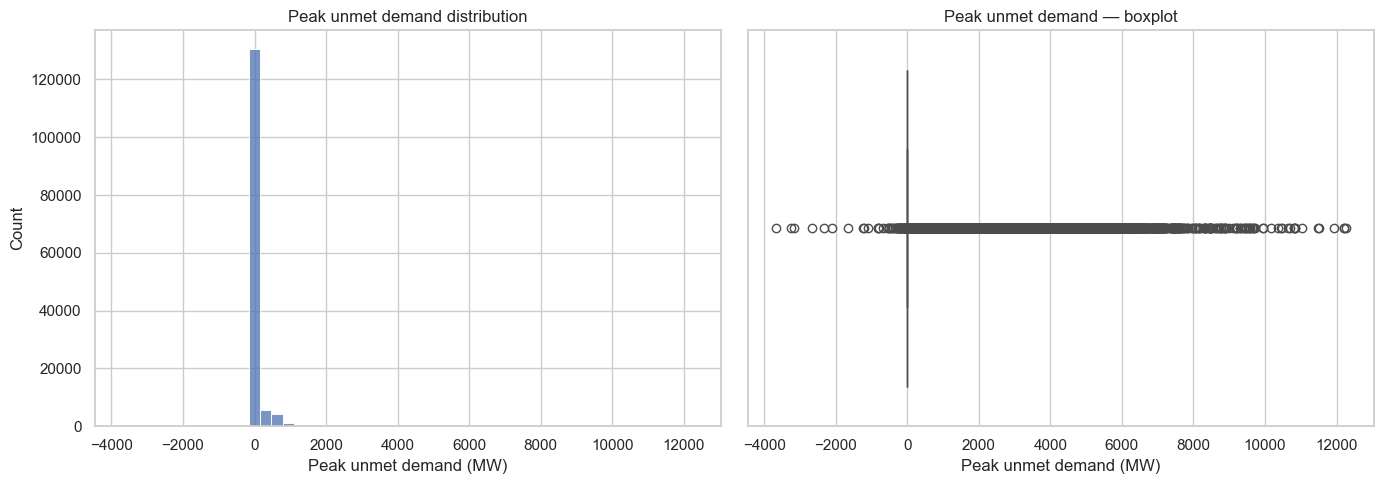

In [39]:

# Distribution of peak unmet demand
values = peak_unmet["Value"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(values, bins=50, ax=axes[0])
axes[0].set_title("Peak unmet demand distribution")
axes[0].set_xlabel("Peak unmet demand (MW)")

sns.boxplot(x=values, ax=axes[1])
axes[1].set_title("Peak unmet demand — boxplot")
axes[1].set_xlabel("Peak unmet demand (MW)")

plt.tight_layout()
plt.show()


In [40]:

# Zero, positive, negative and missing observations
unmet_values = peak_unmet["Value"]

summary = pd.Series({
    "Total observations": len(unmet_values),
    "Missing": unmet_values.isna().sum(),
    "Zero": unmet_values.eq(0).sum(),
    "Positive": unmet_values.gt(0).sum(),
    "Negative": unmet_values.lt(0).sum(),
})

display(summary.to_frame("Count"))

observed = unmet_values.dropna()

print(
    "Positive observations (% of non-missing):",
    round(100 * observed.gt(0).mean(), 2), "%"
)


,Count
Total observations,154245
Missing,9839
Zero,103855
Positive,40451
Negative,100


Positive observations (% of non-missing): 28.01 %


In [41]:

# Shortfall quantiles
print("All observed values:")
display(peak_unmet["Value"].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99]
))

positive_unmet = peak_unmet.loc[
    peak_unmet["Value"] > 0, "Value"
]

print("Positive shortfall values only:")
display(positive_unmet.quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99]
))


All observed values:


0.50       0.00
0.75       1.00
0.90     150.00
0.95     513.00
0.99    2619.95
Name: Value, dtype: float64

Positive shortfall values only:


0.50      46.0
0.75     338.0
0.90     810.0
0.95    1860.0
0.99    5650.5
Name: Value, dtype: float64

### State-wise shortfalls

In [42]:

# State-wise unmet demand statistics
state_unmet_summary = (
    peak_unmet.groupby("State")["Value"]
    .agg(
        observations="count",
        mean_MW="mean",
        median_MW="median",
        maximum_MW="max",
        std_MW="std"
    )
)

positive_days = (
    peak_unmet.assign(positive=peak_unmet["Value"].gt(0))
    .groupby("State")["positive"]
    .sum()
)

state_unmet_summary["positive_observations"] = positive_days
state_unmet_summary["positive_frequency_pct"] = (
    100 * positive_days / state_unmet_summary["observations"]
)

display(
    state_unmet_summary.sort_values("mean_MW", ascending=False)
)


,observations,mean_MW,median_MW,maximum_MW,std_MW,positive_observations,positive_frequency_pct
State,,,,,,,
Total,3951,1977.353075,838.0,12251.0,2272.311986,3803,96.254113
Uttar Pradesh,3955,720.628066,0.0,6120.0,1130.627969,1953,49.380531
Jammu and Kashmir,3955,313.791150,374.0,1219.0,222.348706,3198,80.859671
Karnataka,3952,161.200152,0.0,2000.0,301.967771,1147,29.023279
Tamil Nadu,3952,155.148026,0.0,2910.0,403.972376,695,17.586032
Andhra Pradesh,3952,106.484312,0.0,3800.0,382.164776,464,11.740891
Bihar,3955,75.189128,0.0,1738.0,160.112289,1170,29.582807
Maharashtra,3955,70.194690,0.0,2986.0,191.509796,1189,30.063211
Assam,3955,69.456131,39.0,473.0,78.287276,2891,73.097345


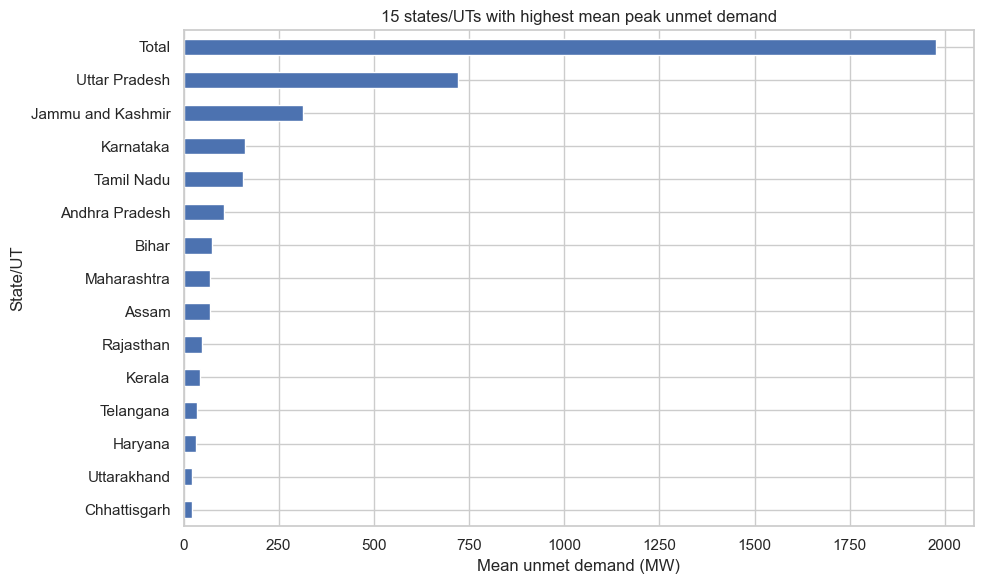

In [43]:

# Compare states by mean shortfall
top_states = (
    state_unmet_summary.nlargest(15, "mean_MW")
    .sort_values("mean_MW")
)

top_states["mean_MW"].plot(kind="barh", figsize=(10, 6))
plt.title("15 states/UTs with highest mean peak unmet demand")
plt.xlabel("Mean unmet demand (MW)")
plt.ylabel("State/UT")
plt.tight_layout()
plt.show()


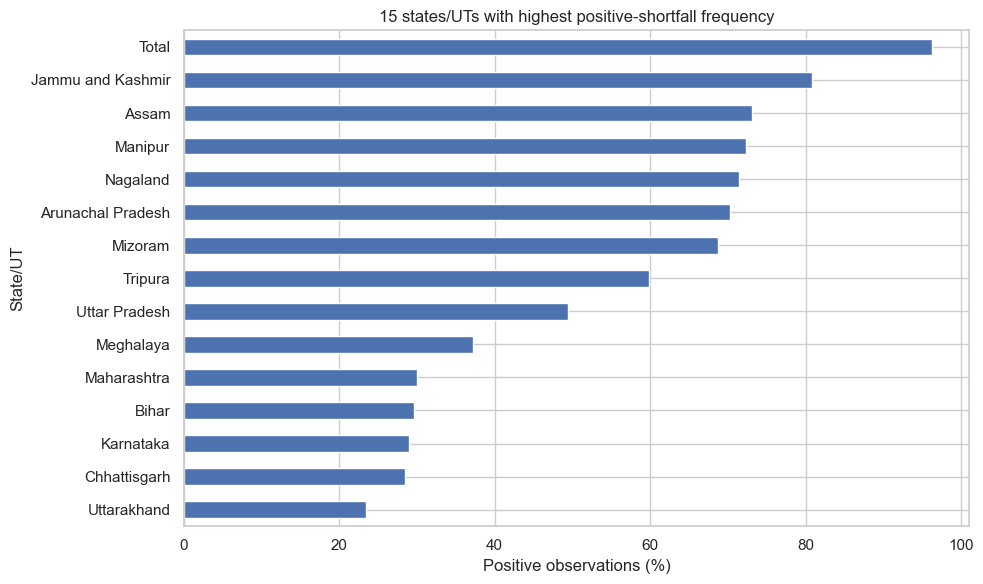

In [44]:

# Compare states by shortfall frequency
top_frequency = (
    state_unmet_summary.nlargest(15, "positive_frequency_pct")
    .sort_values("positive_frequency_pct")
)

top_frequency["positive_frequency_pct"].plot(
    kind="barh", figsize=(10, 6)
)

plt.title("15 states/UTs with highest positive-shortfall frequency")
plt.xlabel("Positive observations (%)")
plt.ylabel("State/UT")
plt.tight_layout()
plt.show()


### Temporal Analysis

In [45]:
unmet["Year"] = unmet["Date"].dt.year
unmet["Month"] = unmet["Date"].dt.month

annual = unmet.groupby("Year")["Unmet_MW"].mean()
monthly = unmet.groupby("Month")["Unmet_MW"].mean().reindex(range(1, 13))

annual.plot(marker="o")
plt.title("Annual Mean Unmet Demand")
plt.xlabel("Year")
plt.ylabel("Mean unmet demand (MW)")
plt.show()

monthly.plot(kind="bar")
plt.title("Mean Unmet Demand by Month")
plt.xlabel("Month")
plt.ylabel("Mean unmet demand (MW)")
plt.xticks(
    range(12),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
    rotation=0
)
plt.show()

NameError: name 'unmet' is not defined